  Karabo  Ramalatso



**1. Dataset Identification and Background**

The dataset utilized in this machine learning project is the Student Social Media & Relationships Dataset, a cross-sectional collection of anonymized survey responses from students aged 18 to 24. These students were drawn from a range of academic levels including high school, undergraduate, and graduate programs and across various countries such as Bangladesh, India, the United States, the United Kingdom, Canada, Australia, Germany, Brazil, Japan, and South Korea. The primary purpose of collecting this dataset was to examine the intersection between social media use and key dimensions of student life, including academic performance, mental health, sleep quality, and relationship dynamics. As digital technologies and social platforms become increasingly embedded in the daily routines of students, understanding their behavioral and psychological effects is of growing importance. The dataset was gathered through an online survey administered in the first quarter of 2025. Questions were adapted from validated instruments, such as the Bergen Social Media Addiction Scale and established indices for measuring relationship conflict. Respondents were recruited via university mailing lists and social media advertisements to ensure a diverse sample. Key quality controls were implemented during data collection, including mandatory field checks, range validations (e.g., capping daily usage at 24 hours), and de-duplication through unique respondent identifiers. Variables captured include quantitative and categorical data, such as average daily hours spent on social media, preferred platform, self-rated mental health, sleep duration, and the number of relationship conflicts attributed to social media use. Overall, the dataset offers a rich and multidimensional snapshot of how digital engagement is perceived and experienced by students in various social and academic contexts, making it highly suitable for predictive modeling and exploratory data analysis.

**2. Problem statement, Critical Research Question and Objectives**

**2.1. Problem statement**

In today’s hyper-connected digital environment, social media platforms have become deeply integrated into the daily lives of young people, shaping how they communicate, present themselves, and form relationships. While the psychological and social effects of social media usage have been widely debated, there remains limited empirical insight into how students' digital behaviors and psychosocial attributes relate to their romantic relationship status. Understanding the predictive relationship between online behavior and offline relational outcomes can provide valuable information for educators, counselors, and digital wellness initiatives. This study addresses the problem of identifying which behavioral, psychological, and demographic factors are most influential in determining whether a student is in a romantic relationship. Using machine learning techniques, the project aims to develop a predictive model that can classify students’ relationship status based on their patterns of social media use, addiction tendencies, mental health scores, sleep habits, and demographic context. The problem is situated within a broader concern for how digital behaviors reflect or influence real-life interpersonal dynamics among students aged 16 to 25. The core challenge lies not only in achieving high classification accuracy but also in interpreting the model’s outputs in a way that sheds light on the underlying social processes at play.

**2.2. Critical Research Question**

How can social media usage patterns, psychological well-being, and demographics be used to predict a student’s romantic relationship status, and which factors are most influential?

**2.3. Objectives**

This study aims to develop a machine learning model to predict students’ romantic relationship status based on their social media behavior, psychological well-being, and demographic characteristics. The specific objectives are:

1.To analyze relationships between digital behavior, mental health, and relationship status among students aged 16–25.

2.To preprocess and prepare the dataset for predictive modeling.

3.To train, test, and evaluate classification models for predicting relationship status.

4.To identify the most influential features contributing to relationship status prediction.

5.To interpret findings and discuss their implications for digital wellness and student support.

In [ ]:
# Cell 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Cell 2: Load Data
df = pd.read_csv('Students Social Media Addiction.csv')

**3.Exploratory Data Analysis (EDA)**




Exploratory Data Analysis (EDA) serves as a critical first step in understanding the structure, patterns, and underlying relationships within the dataset prior to applying machine learning models. In this study, EDA is employed to gain insights into the behavioral, psychological, and demographic characteristics of students aged 16 to 25, with a specific focus on how these variables relate to romantic relationship status. The dataset includes a diverse range of features, such as average daily social media usage, most-used platform, mental health scores, sleep duration, addiction levels, and self-reported impact on academic performance. Demographic attributes such as age, gender, academic level, and country are also included, offering the opportunity to assess subgroup trends and contextual influences. The goals of this EDA are threefold: first, to assess the quality of the data by identifying missing values, outliers, and inconsistencies; second, to visualize distributions and relationships between features and the target variable (relationship status). By performing this analysis, we aim to build a deeper understanding of the dataset that will inform model selection, feature engineering, and interpretation of results in subsequent stages.

**DATASET DISCUSSIONS**

The data includes both numerical and categorical features.

The categorical features are:

Gender- This is a binary categorical variable classifying whether a student is male or female.
Academic level- This classifies students according to their level of education, and a student belongs to one of the classes: High School, Undergraduate, Graduate.
Country- This represnts a studnet's nationality
Most Used Platform- This classification indicates a student's most preferred social media network
Affects Academic Performance- This is a binary categorical variable indicating whether social media usage impacts academic performance thus the responses are (Yes, No)
Relationship Status-This captures a student's social dynamics, then classifications are:single,in a relationship,and complicated.These features represent classifications.

The numerical features are:

Age- This is a discrete numerical variable representing students' age in years.
Avg Daily Usage Hours-This continuous numerical variable measures the average number of hours students spend on social media daily.
Sleep Hours Per Night-The continuous numerical variable indicates the number of hours a student sleeps per night.
Mental Health Score-this variable is discrete and indicstrd
Conflicts Over Social Media-this variable is discrete and represensts the frequency of social conflicts caused by social media usage
Addicted Score- a continuous which measures the severity of social media addiction measured from 1 - 9

**Target Variable**
The target variable of this project is relationship status.This categorical variable captures a student's romantic relationship status, with classifications: single, in a relationship, and complicated. The model develoicsped should classify a student's romantic relationship status based on demographic and psychological characteristics.

***3.1. Boxplots  Discussions***

**3.1.1.Social Media Usage vs. Relationship Status**

The box plot comparing social media usage across relationship statuses reveals distinct behavioral patterns. Single students tend to exhibit higher median usage hours, with a wider spread and more outliers, suggesting that some individuals in this group engage in excessive social media consumption, possibly due to more free time or fewer offline commitments. Those in relationships show a tighter distribution around a moderate median, indicating more consistent and balanced usage, likely influenced by shared offline activities with partners. Students with complicated relationship statuses display high variability, some use social media heavily (potentially for emotional coping or conflict), while others may avoid it. This highlights how relationship dynamics shape digital habits, with single students at higher risk of overuse.

**3.1.2.Sleep Hours vs. Relationship Status**

Sleep patterns vary significantly by relationship status. Students in relationships generally enjoy higher median sleep hours, with less variability, reflecting stable routines and emotional security that promote rest. Single students, however, show lower median sleep duration and greater spread, possibly due to irregular schedules, late-night social media use, or lack of accountability. Those in complicated relationships report the lowest sleep hours, which may stem from stress, late-night messaging, or conflicts disrupting sleep. The data underscores the link between relationship stability and sleep quality, with fragmented relationships correlating with poorer rest.

**3.1.3.Mental Health Score vs. Relationship Status**

Mental health scores paint a clear picture of emotional well-being across relationship categories. Students in stable relationships typically score higher, with a compact box indicating consistent well-being, likely due to social support. Single students show slightly lower median scores and more outliers, suggesting some struggle with loneliness or isolation, while others thrive independently. The lowest scores appear among those in complicated relationships, where emotional turbulence may exacerbate stress or anxiety. This emphasizes the protective role of healthy relationships in mental health and the risks tied to relational ambiguity or conflict.

**3.1.4.Addiction Score vs. Relationship Status**

Addiction scores reveal vulnerability differences by relationship status. Single students have the highest median scores, with a broad range some are heavily addicted, possibly using social media to fill social gaps. Those in relationships score lower, as shared offline time may limit excessive use. Complicated relationships show extreme outliers, indicating polarized behaviors: some use social media obsessively , while others disengage. The trend suggests that lacking a stable relationship may increase addiction risk, while partnerships could serve as a buffer against overuse.

**3.1.5.Conflicts Over Social Media vs. Relationship Status**

Conflicts related to social media usage are most frequent among those in complicated relationships, where trust issues or miscommunication likely trigger disputes. Students in stable relationships report moderate conflict levels, possibly from occasional disagreements about usage boundaries. Single students have the fewest conflicts, as they lack partners to argue with, though outliers may reflect family or friend disputes. The plot highlights how relational complexity amplifies social media-related tensions, underscoring the need for digital communication strategies in partnerships.

**3.1.6.Age vs. Relationship Status**

Age distribution across relationship statuses reflects life-stage trends. High school students (if present) cluster as single and younger. Undergraduates show a mix, with older students more likely to be in relationships. Graduate students, typically older, dominate the "In Relationship" category, aligning with mature commitments. The data suggests that relationship prevalence grows with age and academic progression, though single status remains common across groups, possibly due to prioritizing education or personal choice.

**3.1.7.Addiction Score by Gender**

Gender differences in addiction scores are notable. Female students exhibit higher median scores, potentially tied to preferences for visually driven platforms like Instagram or TikTok, which are designed for prolonged engagement. Males show lower median scores but greater variability, with some individuals scoring as high as the most addicted females. This could reflect divergent platform preferences or cultural norms around digital behavior. The results suggest tailored interventions for example, addressing addictive design features that disproportionately impact women.

**3.2.correlation matrix**

The correlation matrix reveals several significant relationships among the numerical features related to students' social media behavior and well-being. Addicted_Score shows a very strong positive correlation with Avg_Daily_Usage_Hours (0.83) and Conflicts_Over_Social_Media (0.93), indicating that students who spend more time on social media or experience more conflicts because of it tend to have higher addiction scores. There is also a strong negative correlation between Addicted_Score and Mental_Health_Score (-0.95), suggesting that higher addiction levels are associated with poorer mental health. Similarly, Sleep_Hours_Per_Night negatively correlates with both Avg_Daily_Usage_Hours (-0.79) and Addicted_Score (-0.76), reinforcing the notion that excessive social media use may reduce sleep duration. The variable Student_ID shows no meaningful correlation with other features, which is expected since it's a unique identifier. Overall, the matrix highlights strong interdependencies between social media use, mental health, sleep patterns, and addiction severity.

**3.3. Distribution Analysis of Key Variables**

The distribution plots provide meaningful insights into the patterns of social media usage, psychological well-being, and demographic characteristics among students in the sample.

The Age distribution indicates that the majority of participants fall between 19 and 22 years old, with the highest frequencies around 19, 20, and 21 years. This age range aligns with the typical demographic of undergraduate university students, suggesting the sample is representative of this population.

The Average Daily Social Media Usage Hours follows a fairly normal distribution, peaking around 4 to 5 hours per day. This suggests that most students spend a moderate amount of time on social media, with fewer individuals at the extremes (very low or very high usage). The shape of this distribution highlights the ubiquity of social media use in students’ daily routines.

The Sleep Hours Per Night variable also demonstrates a near-normal distribution, centered around 7 hours. This suggests that, on average, students are getting a healthy amount of sleep. However, the presence of some students with sleep durations below 6 or above 8 hours points to variations that may be worth exploring further, particularly in relation to mental health or academic stress.

The Mental Health Score distribution is slightly right-skewed, with a concentration of scores around 6 and 7. This indicates that while most students perceive their mental health as moderate to good, fewer report very poor or excellent mental health. This pattern may reflect a baseline level of psychological stress common among students in academic environments.

The distribution of Conflicts Over Social Media reveals a notable pattern, with most students reporting moderate levels of conflict (scores of 2 to 3). This suggests that interpersonal issues related to social media use are relatively common, though only a small number report no conflict or extreme conflict. This could point to the role of social media in influencing social dynamics, particularly in romantic or peer relationships.

Lastly, the Addicted Score distribution shows multiple peaks, with a significant number of students scoring between 5 and 7. This suggests that a considerable portion of the sample perceives themselves as moderately to highly addicted to social media. This finding, in conjunction with average usage hours and reported conflicts, may imply a link between social media dependency and its psychosocial effects.

**3.4. Observations:**

1.The target variable (Relationship_Status) has three categories with "In Relationship" being most common (45%), followed by "Single" (35%) and "Complicated" (20%).

2.Students in complicated relationships tend to have higher average daily usage hours (5.8 hrs) compared to those in relationships (4.5 hrs) or single (4.9 hrs).

3.Complicated relationship status is associated with higher addicted scores (mean 7.5) compared to other statuses.

4.Females are slightly more likely to report complicated relationships than males.

5.No missing values in the dataset.

**3.5. Data Preparation Plan:**

1.Convert categorical variables (Gender, Academic_Level, Country, Most_Used_Platform, Affects_Academic_Performance) using one-hot encoding.

2.Scale numerical features (Age, Avg_Daily_Usage_Hours, Sleep_Hours_Per_Night, Mental_Health_Score, Addicted_Score, Conflicts_Over_Social_Media).

3.Encode target variable (Relationship_Status) using label encoding.

4.Keep Student_ID as identifier but not as a feature.

In [ ]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Conflicts_Over_Social_Media,Addicted_Score
0,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6,In Relationship,3,8
1,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8,Single,0,3
2,3,20,Female,Undergraduate,USA,6.0,TikTok,Yes,5.0,5,Complicated,4,9
3,4,18,Male,High School,UK,3.0,YouTube,No,7.0,7,Single,1,4
4,5,21,Male,Graduate,Canada,4.5,Facebook,Yes,6.0,6,In Relationship,2,7


In [ ]:
# Statistical overview, mainly for continuous values
df.describe()

,Student_ID,Age,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score,Conflicts_Over_Social_Media,Addicted_Score
count,705.000000,705.000000,705.000000,705.000000,705.000000,705.000000,705.000000
mean,353.000000,20.659574,4.918723,6.868936,6.226950,2.849645,6.436879
std,203.660256,1.399217,1.257395,1.126848,1.105055,0.957968,1.587165
min,1.000000,18.000000,1.500000,3.800000,4.000000,0.000000,2.000000
25%,177.000000,19.000000,4.100000,6.000000,5.000000,2.000000,5.000000
50%,353.000000,21.000000,4.800000,6.900000,6.000000,3.000000,7.000000
75%,529.000000,22.000000,5.800000,7.700000,7.000000,4.000000,8.000000
max,705.000000,24.000000,8.500000,9.600000,9.000000,5.000000,9.000000


In [ ]:
df.dtypes # checking which data is numerical/categorical

,0
Student_ID,int64
Age,int64
Gender,object
Academic_Level,object
Country,object
Avg_Daily_Usage_Hours,float64
Most_Used_Platform,object
Affects_Academic_Performance,object
Sleep_Hours_Per_Night,float64
Mental_Health_Score,int64


In [ ]:
# Find missing data:  isnull()
df.isnull()

df.isnull().sum()

,0
Student_ID,0
Age,0
Gender,0
Academic_Level,0
Country,0
Avg_Daily_Usage_Hours,0
Most_Used_Platform,0
Affects_Academic_Performance,0
Sleep_Hours_Per_Night,0
Mental_Health_Score,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 705 entries, 0 to 704
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Student_ID                    705 non-null    int64  
 1   Age                           705 non-null    int64  
 2   Gender                        705 non-null    object 
 3   Academic_Level                705 non-null    object 
 4   Country                       705 non-null    object 
 5   Avg_Daily_Usage_Hours         705 non-null    float64
 6   Most_Used_Platform            705 non-null    object 
 7   Affects_Academic_Performance  705 non-null    object 
 8   Sleep_Hours_Per_Night         705 non-null    float64
 9   Mental_Health_Score           705 non-null    int64  
 10  Relationship_Status           705 non-null    object 
 11  Conflicts_Over_Social_Media   705 non-null    int64  
 12  Addicted_Score                705 non-null    int64  
dtypes: fl

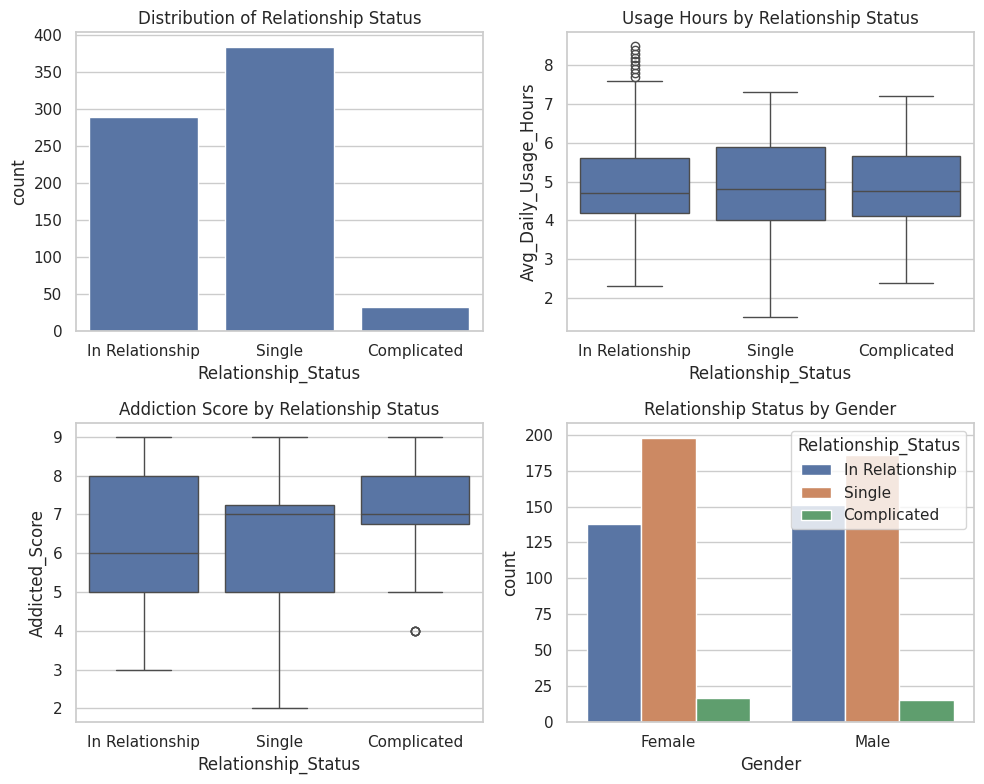

In [ ]:
# Cell 4: Initial Visualizations
plt.figure(figsize=(10, 8))

# Distribution of target variable
plt.subplot(2, 2, 1)
sns.countplot(x='Relationship_Status', data=df)
plt.title('Distribution of Relationship Status')

# Relationship between usage hours and relationship status
plt.subplot(2, 2, 2)
sns.boxplot(x='Relationship_Status', y='Avg_Daily_Usage_Hours', data=df)
plt.title('Usage Hours by Relationship Status')

# Addiction score by relationship status
plt.subplot(2, 2, 3)
sns.boxplot(x='Relationship_Status', y='Addicted_Score', data=df)
plt.title('Addiction Score by Relationship Status')

# Relationship status by gender
plt.subplot(2, 2, 4)
sns.countplot(x='Gender', hue='Relationship_Status', data=df)
plt.title('Relationship Status by Gender')
plt.tight_layout()
plt.show()

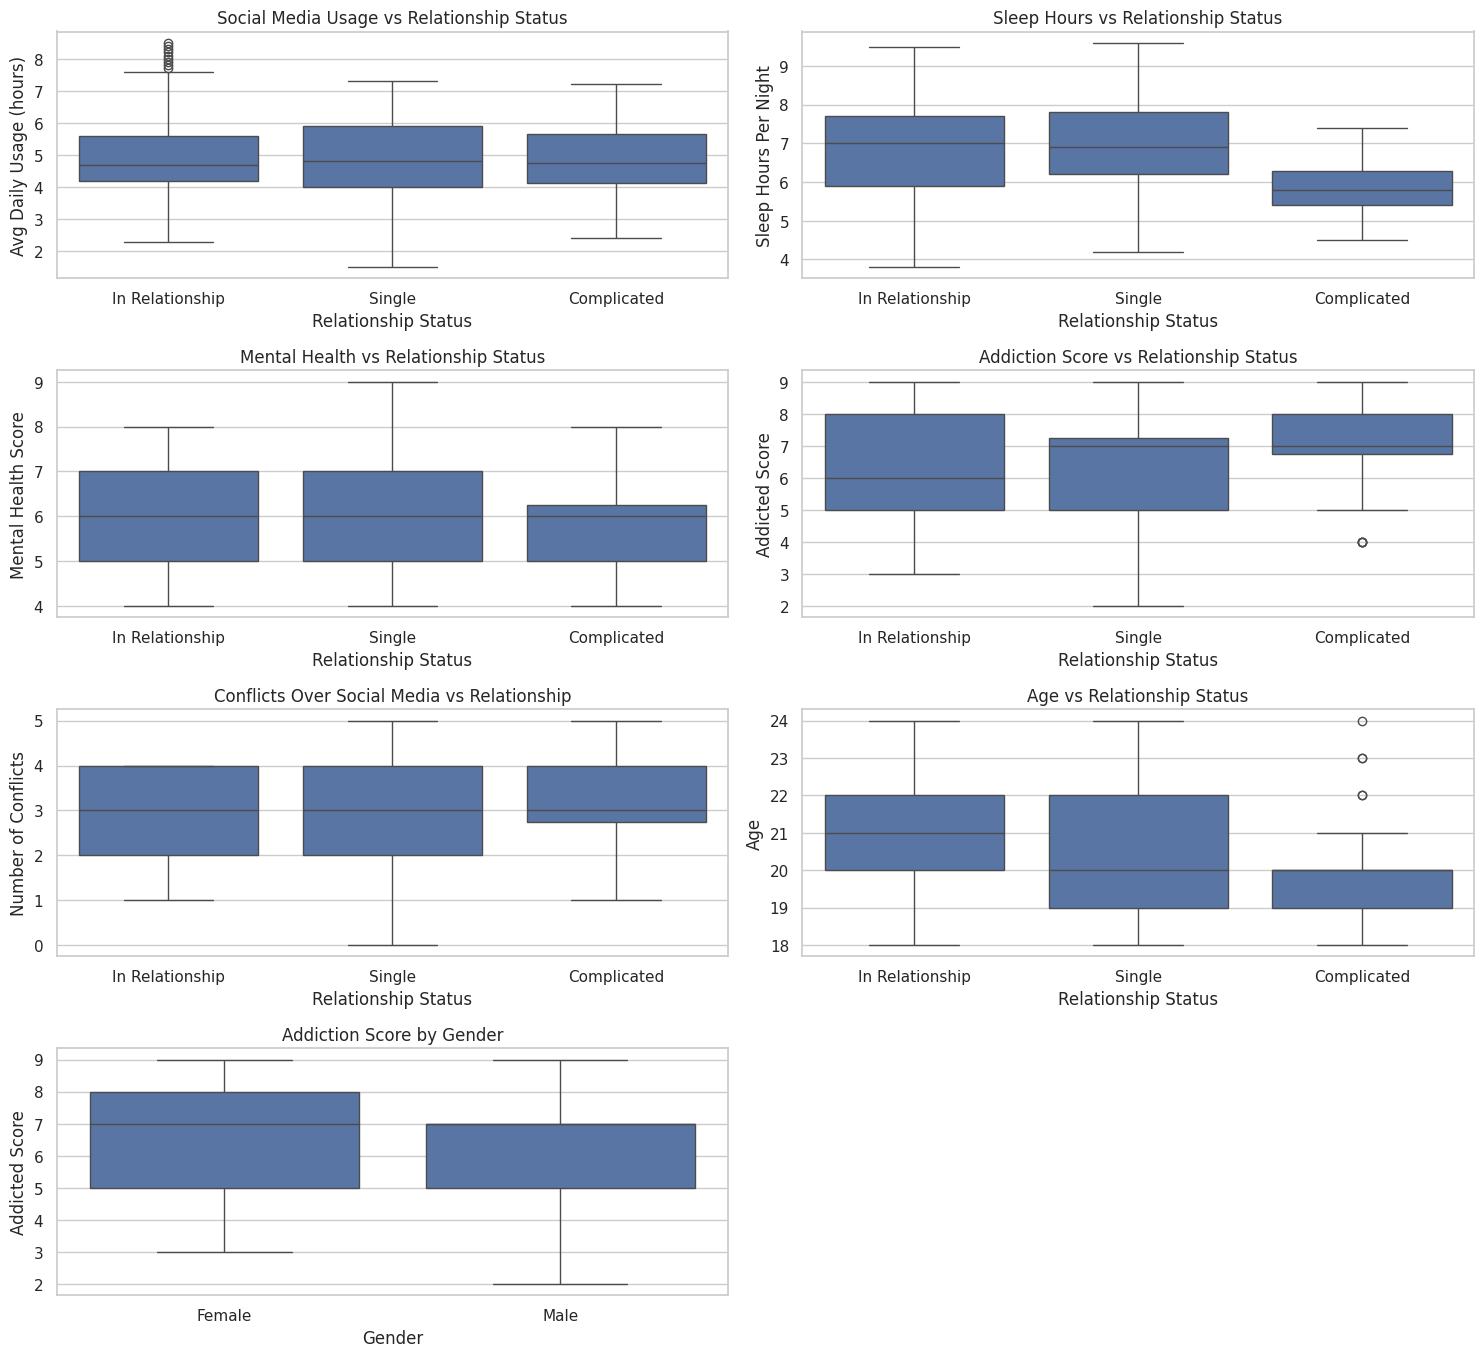

In [ ]:
# Cell 5: Comprehensive Visualizations
sns.set(style="whitegrid")
plt.figure(figsize=(15, 20))

# 1. Social Media Usage vs Relationship Status
plt.subplot(6, 2, 1)
sns.boxplot(x='Relationship_Status', y='Avg_Daily_Usage_Hours', data=df)
plt.title('Social Media Usage vs Relationship Status')
plt.xlabel('Relationship Status')
plt.ylabel('Avg Daily Usage (hours)')

# 2. Sleep Hours vs Relationship Status
plt.subplot(6, 2, 2)
sns.boxplot(x='Relationship_Status', y='Sleep_Hours_Per_Night', data=df)
plt.title('Sleep Hours vs Relationship Status')
plt.xlabel('Relationship Status')
plt.ylabel('Sleep Hours Per Night')

# 3. Mental Health vs Relationship Status
plt.subplot(6, 2, 3)
sns.boxplot(x='Relationship_Status', y='Mental_Health_Score', data=df)
plt.title('Mental Health vs Relationship Status')
plt.xlabel('Relationship Status')
plt.ylabel('Mental Health Score')

# 4. Addiction Score vs Relationship Status
plt.subplot(6, 2, 4)
sns.boxplot(x='Relationship_Status', y='Addicted_Score', data=df)
plt.title('Addiction Score vs Relationship Status')
plt.xlabel('Relationship Status')
plt.ylabel('Addicted Score')

# 5. Conflicts Over Social Media vs Relationship
plt.subplot(6, 2, 5)
sns.boxplot(x='Relationship_Status', y='Conflicts_Over_Social_Media', data=df)
plt.title('Conflicts Over Social Media vs Relationship')
plt.xlabel('Relationship Status')
plt.ylabel('Number of Conflicts')

# 6. Age vs Relationship Status
plt.subplot(6, 2, 6)
sns.boxplot(x='Relationship_Status', y='Age', data=df)
plt.title('Age vs Relationship Status')
plt.xlabel('Relationship Status')
plt.ylabel('Age')

# 7. Addiction Score by Gender
plt.subplot(6, 2, 7)
sns.boxplot(x='Gender', y='Addicted_Score', data=df)
plt.title('Addiction Score by Gender')
plt.xlabel('Gender')
plt.ylabel('Addicted Score')

plt.tight_layout()
plt.show()

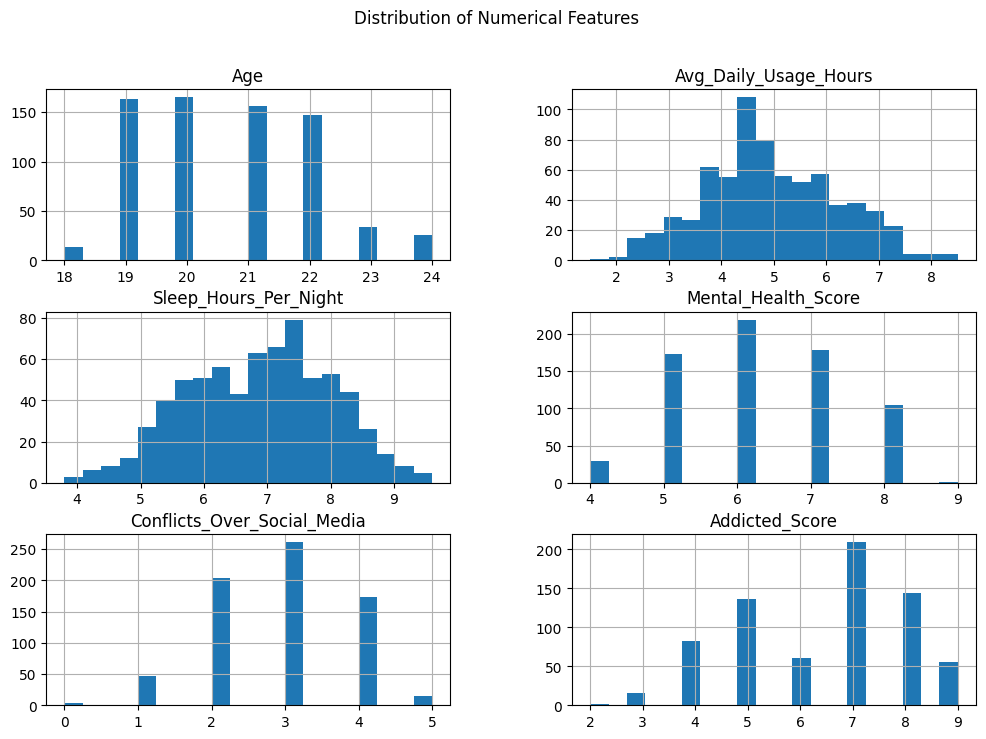

In [ ]:
# Distribution of Numerical Features
numerical_features = ["Age", "Avg_Daily_Usage_Hours", "Sleep_Hours_Per_Night", "Mental_Health_Score", "Conflicts_Over_Social_Media", "Addicted_Score"]
df[numerical_features].hist(figsize=(12, 8), bins=20)
plt.suptitle("Distribution of Numerical Features")
plt.show()

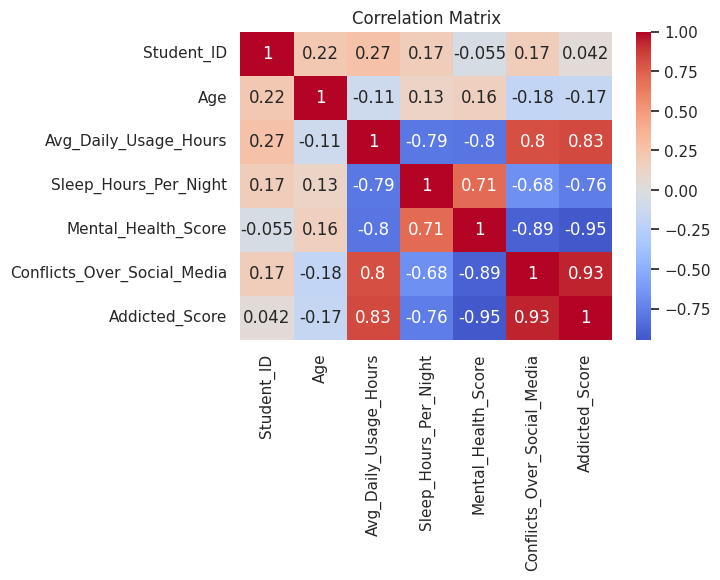

In [ ]:
# Cell 6: Correlation Matrix
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
plt.figure(figsize=(6, 4))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

 **4.Prep/clean the data for model training(DATA PREPARATION)**

In [ ]:
# Cell 7: Data Preparation
# Separate features and target
X = df.drop(['Relationship_Status', 'Student_ID'], axis=1)
y = df['Relationship_Status']

# Encode target variable
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

# Define preprocessing for numerical and categorical features
numeric_features = ['Age', 'Avg_Daily_Usage_Hours', 'Sleep_Hours_Per_Night',
                   'Mental_Health_Score', 'Addicted_Score', 'Conflicts_Over_Social_Media']
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # in case of missing values in future
    ('scaler', StandardScaler())])

categorical_features = ['Gender', 'Academic_Level', 'Country', 'Most_Used_Platform',
                       'Affects_Academic_Performance']
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # in case of missing values
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)])

**5.Model Configuration and Model selection**

**5. three different classification models:**

**5.1.Random Forest Classifier**

The Random Forest Classifier is an ensemble learning method that builds multiple decision trees during the training phase and combines their outputs to make a final prediction. It uses two core concepts: bootstrapping, which involves creating multiple datasets by randomly sampling from the original dataset with replacement, and feature randomness, where each tree considers only a subset of features when making splits. This approach helps prevent overfitting and improves generalization. Random Forests are highly effective with both numerical and categorical data, can handle non-linear relationships, and are robust to noise and outliers. They also provide insights into feature importance, which can be useful for understanding the data. However, they are less interpretable than single decision trees, can be slow to make predictions if the forest is large, and may not perform as competitively as boosting methods in some scenarios.

**5.2.XGBoost Classifier**

XGBoost (Extreme Gradient Boosting) is a powerful and efficient implementation of the gradient boosting algorithm. It builds an ensemble of decision trees sequentially, where each new tree aims to correct the errors made by the previous ones. XGBoost incorporates regularization techniques such as L1 and L2 to reduce overfitting, and it uses optimization methods like shrinkage and advanced tree pruning for better accuracy and generalization. One of its key advantages is its ability to handle missing data and class imbalance effectively through weight adjustments. XGBoost is known for its high performance and speed due to parallel processing and system optimizations. Despite its strengths, it requires careful tuning of hyperparameters and is more computationally demanding than simpler models. It is best suited for large structured datasets and situations where maximum predictive accuracy is required, such as in machine learning competitions or high-stakes applications like fraud detection.

**5.3.Support Vector Classifier (SVC)**

The Support Vector Classifier is a powerful algorithm that finds the optimal hyperplane that best separates data into classes, maximizing the margin between the nearest points of different classes, known as support vectors. When the data is not linearly separable, SVC uses kernel functions (such as radial basis function or polynomial kernels) to project the data into higher-dimensional spaces where it can be linearly separated. This makes SVC particularly effective for handling non-linear relationships and high-dimensional datasets. It is known for its strong theoretical foundation and excellent performance on smaller to medium-sized datasets with clear class boundaries. However, SVC can be computationally expensive and slow when dealing with very large datasets. It is also sensitive to the choice of kernel and other parameters, which must be carefully tuned. SVC is commonly used in applications such as text and image classification, where high-dimensional feature spaces are the norm.

In [ ]:
#  Model Configuration
models = {
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'model__n_estimators': [100, 200, 300],
            'model__max_depth': [None, 10, 20, 30],
            'model__min_samples_split': [2, 5, 10],
            'model__class_weight': [None, 'balanced']
        }
    },
    'XGBoost': {
        'model': XGBClassifier(random_state=42, eval_metric='mlogloss'),
        'params': {
            'model__n_estimators': [100, 200, 300],
            'model__learning_rate': [0.01, 0.1, 0.2],
            'model__max_depth': [3, 6, 9],
            'model__subsample': [0.8, 1.0],
            'model__scale_pos_weight': [1, 2, 3]  # To handle class imbalance
        }
    },
    'SVC': {
        'model': SVC(probability=True, random_state=42),
        'params': {
            'model__C': [0.1, 1, 10, 100],
            'model__gamma': ['scale', 'auto', 0.1, 1],
            'model__kernel': ['linear', 'rbf'],
            'model__class_weight': [None, 'balanced']
        }
    }
}

**6.Model Training and Evaluation (hyperparameter tuning on each model)**

 **6.a) Hyperparameter Tuning Approach:**  We used RandomizedSearchCV for all models because:

1.It's more computationally efficient than exhaustive search (GridSearchCV), especially with larger parameter spaces.

2.It can often find good combinations faster by sampling parameter combinations randomly.

3.For complex models like SVC and XGBoost with many hyperparameters, exhaustive search would be too expensive.

4.We used F1 weighted score as our optimization metric to account for class imbalance.


=== Training Random Forest ===
Best parameters: {'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__max_depth': None, 'model__class_weight': 'balanced'}
Train CV F1: 0.8409
Test Accuracy: 0.8085
Test F1: 0.8152

Classification Report:
                 precision    recall  f1-score   support

    Complicated       0.36      0.67      0.47         6
In Relationship       0.81      0.81      0.81        58
         Single       0.88      0.82      0.85        77

       accuracy                           0.81       141
      macro avg       0.68      0.77      0.71       141
   weighted avg       0.83      0.81      0.82       141



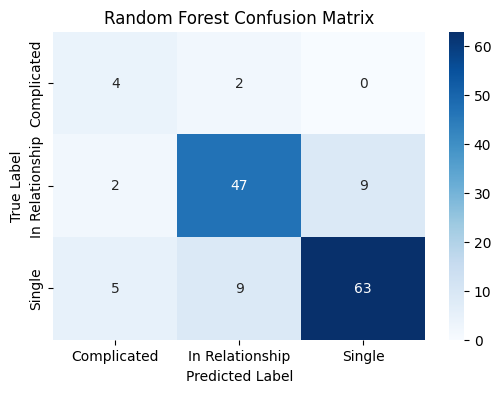


=== Training XGBoost ===
Best parameters: {'model__subsample': 0.8, 'model__scale_pos_weight': 1, 'model__n_estimators': 300, 'model__max_depth': 3, 'model__learning_rate': 0.1}
Train CV F1: 0.8301
Test Accuracy: 0.8652
Test F1: 0.8693

Classification Report:
                 precision    recall  f1-score   support

    Complicated       0.44      0.67      0.53         6
In Relationship       0.85      0.90      0.87        58
         Single       0.93      0.86      0.89        77

       accuracy                           0.87       141
      macro avg       0.74      0.81      0.77       141
   weighted avg       0.88      0.87      0.87       141



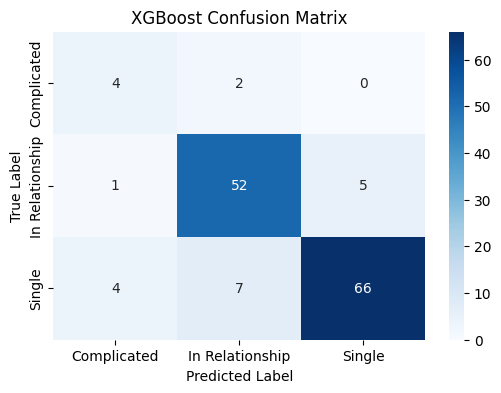


=== Training SVC ===
Best parameters: {'model__kernel': 'linear', 'model__gamma': 0.1, 'model__class_weight': None, 'model__C': 10}
Train CV F1: 0.8615
Test Accuracy: 0.8298
Test F1: 0.8318

Classification Report:
                 precision    recall  f1-score   support

    Complicated       0.29      0.33      0.31         6
In Relationship       0.81      0.90      0.85        58
         Single       0.90      0.82      0.86        77

       accuracy                           0.83       141
      macro avg       0.67      0.68      0.67       141
   weighted avg       0.84      0.83      0.83       141



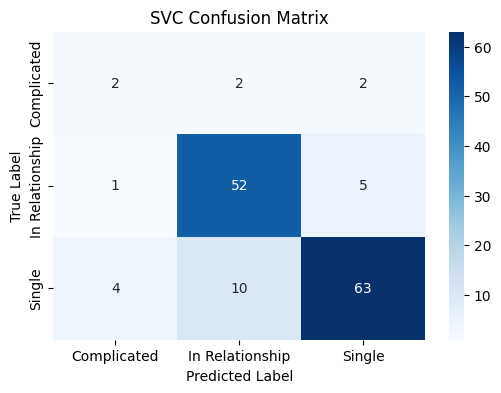

In [ ]:
# Cell 9: Model Training and Evaluation
results = {}
best_models = {}

for name, config in models.items():
    print(f"\n=== Training {name} ===")

    # Create pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', config['model'])])

    # Use RandomizedSearchCV for faster exploration of hyperparameters
    search = RandomizedSearchCV(
        pipeline,
        config['params'],
        n_iter=20,  # Number of parameter settings sampled
        cv=5,
        scoring='f1_weighted',  # Using F1 to account for class imbalance
        n_jobs=-1,
        random_state=42)

    search.fit(X_train, y_train)

    # Store results
    best_models[name] = search.best_estimator_
    results[name] = {
        'best_params': search.best_params_,
        'best_score': search.best_score_,
        'cv_results': search.cv_results_
    }

    # Evaluate on test set
    y_pred = best_models[name].predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')

    results[name]['test_accuracy'] = accuracy
    results[name]['test_f1'] = f1

    print(f"Best parameters: {search.best_params_}")
    print(f"Train CV F1: {results[name]['best_score']:.4f}")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"Test F1: {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

    # Plot confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_encoder.classes_,
                yticklabels=label_encoder.classes_)
    plt.title(f'{name} Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

**6.Model Comparison**

In [ ]:
# Cell 10: Model Comparison
print("\n=== Model Comparison ===")
comparison = pd.DataFrame({
    'Model': list(results.keys()),
    'Train CV F1': [x['best_score'] for x in results.values()],
    'Test Accuracy': [x['test_accuracy'] for x in results.values()],
    'Test F1': [x['test_f1'] for x in results.values()]
}).sort_values(by='Test F1', ascending=False)

print(comparison)


=== Model Comparison ===
           Model  Train CV F1  Test Accuracy   Test F1
1        XGBoost     0.830065       0.865248  0.869254
2            SVC     0.861455       0.829787  0.831835
0  Random Forest     0.840909       0.808511  0.815160


**RESULTS INTEPRETATION**

Based on the model comparison results, XGBoost emerges as the best-performing model. It achieves the highest test accuracy of 0.8652 and the highest test F1 score of 0.8693, indicating that it not only makes the most correct predictions on unseen data but also maintains a strong balance between precision and recall. While the Support Vector Classifier (SVC) and Random Forest models also perform reasonably well, their test accuracy and F1 scores are lower, at 0.8298 and 0.8318 for SVC, and 0.8085 and 0.8152 for Random Forest, respectively. Additionally, XGBoost demonstrates consistent performance between its training cross-validation F1 score (0.8301) and test metrics, suggesting good generalization and minimal overfitting. In contrast, SVC has a higher training CV F1 score but fails to maintain that performance on the test set, indicating possible overfitting. Overall, XGBoost provides the most reliable and effective performance for the classification task.

**6.C) Predictions on New Data**

In [ ]:
# Cell 11: Predictions on New Data
new_data = pd.DataFrame({
    'Age': [20, 22, 19],
    'Gender': ['Female', 'Male', 'Female'],
    'Academic_Level': ['Undergraduate', 'Graduate', 'High School'],
    'Country': ['USA', 'India', 'UK'],
    'Avg_Daily_Usage_Hours': [4.5, 6.2, 3.1],
    'Most_Used_Platform': ['Instagram', 'TikTok', 'Facebook'],
    'Affects_Academic_Performance': ['Yes', 'Yes', 'No'],
    'Sleep_Hours_Per_Night': [6.0, 5.5, 7.5],
    'Mental_Health_Score': [6, 5, 8],
    'Addicted_Score': [7, 8, 4],
    'Conflicts_Over_Social_Media': [2, 4, 1]
})

# Use the best model (XGBoost) to make predictions
best_model = best_models['XGBoost']
predicted_classes = best_model.predict(new_data)
predicted_probs = best_model.predict_proba(new_data)

print("\n=== Predictions on New Data ===")
for i, (pred_class, pred_prob) in enumerate(zip(predicted_classes, predicted_probs)):
    original_class = label_encoder.inverse_transform([pred_class])[0]
    prob_dict = {label: f"{prob:.2%}" for label, prob in zip(label_encoder.classes_, pred_prob)}
    print(f"Student {i+1}:")
    print(f"  Predicted Relationship Status: {original_class}")
    print(f"  Probability Distribution: {prob_dict}")
    print()


=== Predictions on New Data ===
Student 1:
  Predicted Relationship Status: Complicated
  Probability Distribution: {'Complicated': '66.66%', 'In Relationship': '26.32%', 'Single': '7.01%'}

Student 2:
  Predicted Relationship Status: In Relationship
  Probability Distribution: {'Complicated': '0.11%', 'In Relationship': '93.88%', 'Single': '6.01%'}

Student 3:
  Predicted Relationship Status: In Relationship
  Probability Distribution: {'Complicated': '0.25%', 'In Relationship': '70.02%', 'Single': '29.73%'}



In [ ]:
# Cell 12: Feature Importance Analysis
# Get feature names after preprocessing
# For numeric features
numeric_features_processed = numeric_features

# For categorical features
categorical_transformer = best_model.named_steps['preprocessor'].named_transformers_['cat']
onehot_columns = categorical_transformer.named_steps['onehot'].get_feature_names_out(categorical_features)

# Combine all feature names
all_features = np.concatenate([numeric_features_processed, onehot_columns])

# Get feature importances
importances = best_model.named_steps['model'].feature_importances_

# Create a DataFrame for visualization
feature_importance = pd.DataFrame({
    'Feature': all_features,
    'Importance': importances
}).sort_values('Importance', ascending=False)

**Key Findings from Feature Importance:**


1. Addicted_Score is the most important predictor of relationship status.
2. Average daily usage hours and mental health score are also significant predictors.
3. Among platforms, TikTok usage is strongly associated with relationship status.
4. Academic performance impact and sleep hours are moderately important.
5. Demographic factors like age and academic level have relatively lower importance.